# 02 — Da seleção fotométrica à validação espectroscópica

Workshop SAB — AI-Scope / ADSS

**Pergunta científica:** depois de selecionar candidatos em um catálogo, quais deles possuem informação espectroscópica independente?

O exemplo usa uma tabela local de alvos e faz o crossmatch no servidor com DESI DR1. Isso evita baixar um catálogo espectroscópico inteiro apenas para cruzá-lo localmente.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import adss

BASE_URL = "https://ai-scope.cbpf.br/"

cl = adss.ADSSClient(base_url=BASE_URL)

In [2]:
# Use a saída do notebook anterior ou substitua por sua própria lista de alvos.
# Exemplo mínimo para permitir execução independente:
targets = pd.read_csv("outputs/cluster_1.csv")

In [3]:
targets

,source_id,ra,dec,radius_deg,pmra,pmdec,pmra_error,pmdec_error,parallax,parallax_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,ruwe,kinematic_excess
0,2686840521431628288,323.324139,-0.880722,0.069110,3.535957,-2.173133,0.114538,0.073543,0.008011,0.113313,17.320658,17.716633,16.747751,0.968882,0.979177,2.002077
1,2686842033259327104,323.216615,-0.902025,0.165845,3.540397,-2.169961,0.119509,0.083477,-0.033886,0.115138,17.649788,18.056982,17.079865,0.977118,1.053021,2.002068
2,2686841208630066176,323.323723,-0.850133,0.047235,3.523109,-2.172632,0.082432,0.045770,-0.009831,0.066133,16.312115,16.360470,16.273584,0.086885,1.005163,2.002033
3,2686843579447556992,323.253369,-0.887782,0.126833,3.523987,-2.174720,0.123127,0.080571,0.130173,0.114084,17.476366,17.879677,16.900747,0.978930,1.036951,2.002006
4,2686850245241277696,323.344394,-0.804620,0.026083,3.551845,-2.166595,0.198749,0.100412,0.172955,0.130352,17.393589,17.130636,16.252893,0.877743,1.163365,2.001873
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
353,2686844266646783872,323.328537,-0.826074,0.034172,3.608585,-2.083400,0.051430,0.030223,-0.021024,0.043483,15.561186,15.965014,14.886327,1.078688,0.935104,1.984347
354,2686846950998135552,323.372174,-0.839668,0.018962,3.343826,-2.173708,0.085897,0.042853,-0.241768,0.059241,16.045662,15.896893,15.394764,0.502129,1.094846,1.984327
355,2686846946706465792,323.383652,-0.838759,0.026117,3.350035,-2.112683,0.082595,0.038944,-0.121880,0.050212,15.921176,15.863598,15.545351,0.318247,0.917976,1.984300
356,2686890343051497344,323.139072,-0.840369,0.224155,3.366053,-2.096690,0.108775,0.088214,0.111751,0.103947,17.169144,17.575636,16.587310,0.988325,1.030786,1.984230


In [4]:
query = """
SELECT
    u.source_id AS input_source_id,
    u.ra AS input_ra,
    u.dec AS input_dec,
    d.id AS desi_id,
    d.ra AS desi_ra,
    d.dec AS desi_dec,
    d.z,
    d.zerr,
    d.zwarn,
    d.spectype,
    d.subtype,
    d.deltachi2,
    dist(u.ra, u.dec, d.ra, d.dec) AS separation_deg
FROM upload.targets AS u
JOIN desi.desi_specz_dr1 AS d
  ON cone(d.ra, d.dec, u.ra, u.dec, 0.0003)
"""

spec = cl.query_and_wait(
    query_text=query,
    mode="astroql",
    file=targets,
    table_name="targets",
).data
spec.head()

Check query status at: https://ai-scope.cbpf.br/queries/376ffefd-eaad-44c8-b750-d7a97ca32b19
Results fetched.


,input_source_id,input_ra,input_dec,desi_id,desi_ra,desi_dec,z,zerr,zwarn,spectype,subtype,deltachi2,separation_deg
0,2686840521431628288,323.324139,-0.880722,39627765992917818,323.324138,-0.880721,-0.000003,0.000004,0,STAR,K,8585.761256,5.941939e-07
1,2686843579447556992,323.253369,-0.887782,39627765992915165,323.253368,-0.887782,-0.000002,0.000007,0,STAR,K,3966.904018,6.009414e-07
2,2686837532134243712,323.306218,-0.993540,39627765992917090,323.306217,-0.993540,-0.000010,0.000010,0,STAR,G,1589.148057,5.581023e-07
3,2686723835760473856,323.226243,-1.277436,39627759948931395,323.226242,-1.277436,-0.000019,0.000003,0,STAR,K,14490.750945,5.956875e-07
4,2686845885849204096,323.427131,-0.867275,39627772032727977,323.427130,-0.867275,0.000019,0.000005,0,STAR,K,6164.995717,5.574753e-07


spectype
STAR    20
Name: count, dtype: int64


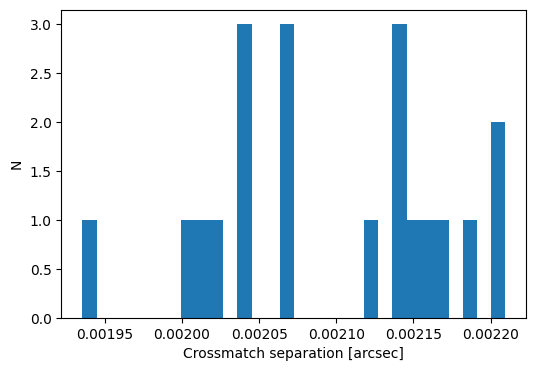

In [5]:
spec["separation_arcsec"] = spec.separation_deg * 3600
print(spec.spectype.value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(6,4))
ax.hist(spec.separation_arcsec.dropna(), bins=30)
ax.set(xlabel="Crossmatch separation [arcsec]", ylabel="N")
plt.show()

### Investigação
Compare a classificação/seleção original dos alvos com `spectype`, `z`, `zwarn` e `deltachi2`. Em um projeto real, este passo pode transformar um conjunto de candidatos puramente fotométricos em uma amostra de validação independente.